In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    LeaveOneOut,
    GridSearchCV,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# ==========================================
# 1. LÄS IN DATA
# ==========================================

data = pd.read_csv("data_grupp_13.csv")

display(data.head())
data.info()

print("\nSaknade värden:")
print(data.isnull().sum())

print("\nFördelning mellan klasser:")
print(data["target"].value_counts())

X = data.drop(columns=["target"])
y = data["target"]


# ==========================================
# 2. SKAPA VALIDERING
# ==========================================

cv_5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

loo = LeaveOneOut()


# ==========================================
# 3. SKAPA MODELLER
# ==========================================

# kNN – skalning görs separat i varje fold
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier())
])

# Random Forest – behöver inte standardiseras
random_forest = RandomForestClassifier(
    random_state=42
)


,besok_per_manad,snittorder_kr,tid_pa_sajt_sek,returgrad,kundtjanst_arenden,rabattkod_andel,target
0,11.9,1690.0,261.0,0.36,5.3,0.24,Risk_for_churn
1,16.5,2993.0,770.0,0.10,0.0,0.36,Lojal_stamkund
2,17.7,536.0,102.0,0.00,1.4,0.85,Fyndjagare
3,10.4,1834.0,355.0,0.04,0.2,0.26,Lojal_stamkund
4,5.2,942.0,165.0,0.54,2.6,0.42,Risk_for_churn


<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   besok_per_manad     240 non-null    float64
 1   snittorder_kr       240 non-null    float64
 2   tid_pa_sajt_sek     240 non-null    float64
 3   returgrad           240 non-null    float64
 4   kundtjanst_arenden  240 non-null    float64
 5   rabattkod_andel     240 non-null    float64
 6   target              240 non-null    str    
dtypes: float64(6), str(1)
memory usage: 13.3 KB

Saknade värden:
besok_per_manad       0
snittorder_kr         0
tid_pa_sajt_sek       0
returgrad             0
kundtjanst_arenden    0
rabattkod_andel       0
target                0
dtype: int64

Fördelning mellan klasser:
target
Risk_for_churn    80
Lojal_stamkund    80
Fyndjagare        80
Name: count, dtype: int64


In [11]:
# ==========================================
# 4. HYPERPARAMETRAR
# ==========================================

# kNN: 5 värden för n_neighbors och 4 för p
knn_param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11],
    "classifier__p": [1, 2, 3, 4]
}

# Random Forest: 4 värden för varje parameter
rf_param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [None, 5, 10, 15]
}


# ==========================================
# 5. GRID SEARCH – kNN
# ==========================================

knn_grid = GridSearchCV(
    estimator=knn,
    param_grid=knn_param_grid,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    cv=cv_5,
    n_jobs=-1
)

start = time.perf_counter()
knn_grid.fit(X, y)
knn_grid_time = time.perf_counter() - start

print("Bästa kNN-parametrar:")
print(knn_grid.best_params_)

print("Bästa kNN F1 Macro:")
print(knn_grid.best_score_)

print("Grid Search-tid kNN:")
print(round(knn_grid_time, 4), "sekunder")


# ==========================================
# 6. GRID SEARCH – RANDOM FOREST
# ==========================================

rf_grid = GridSearchCV(
    estimator=random_forest,
    param_grid=rf_param_grid,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    cv=cv_5,
    n_jobs=-1
)

start = time.perf_counter()
rf_grid.fit(X, y)
rf_grid_time = time.perf_counter() - start

print("\nBästa Random Forest-parametrar:")
print(rf_grid.best_params_)

print("Bästa Random Forest F1 Macro:")
print(rf_grid.best_score_)

print("Grid Search-tid Random Forest:")
print(round(rf_grid_time, 4), "sekunder")


Bästa kNN-parametrar:
{'classifier__n_neighbors': 3, 'classifier__p': 1}
Bästa kNN F1 Macro:
1.0
Grid Search-tid kNN:
0.2316 sekunder

Bästa Random Forest-parametrar:
{'max_depth': None, 'n_estimators': 50}
Bästa Random Forest F1 Macro:
0.9958292603453893
Grid Search-tid Random Forest:
1.4728 sekunder


In [12]:

# ==========================================
# 7. RESULTAT FRÅN GRID SEARCH
# ==========================================

# kNN-resultat
knn_results = pd.DataFrame(knn_grid.cv_results_)

knn_results = knn_results[[
    "param_classifier__n_neighbors",
    "param_classifier__p",
    "mean_test_accuracy",
    "std_test_accuracy",
    "mean_test_f1_macro",
    "std_test_f1_macro"
]]

knn_results = knn_results.sort_values(
    "mean_test_f1_macro",
    ascending=False
)

print("Alla kNN-kombinationer:")
display(knn_results.round(4))


# Random Forest-resultat
rf_results = pd.DataFrame(rf_grid.cv_results_)

rf_results = rf_results[[
    "param_n_estimators",
    "param_max_depth",
    "mean_test_accuracy",
    "std_test_accuracy",
    "mean_test_f1_macro",
    "std_test_f1_macro"
]]

rf_results = rf_results.sort_values(
    "mean_test_f1_macro",
    ascending=False
)

print("Alla Random Forest-kombinationer:")
display(rf_results.round(4))


# Spara resultaten
knn_results.to_csv("knn_grid_results.csv", index=False)
rf_results.to_csv("random_forest_grid_results.csv", index=False)


Alla kNN-kombinationer:


,param_classifier__n_neighbors,param_classifier__p,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,3,1,1.0000,0.0000,1.0000,0.0000
8,7,1,1.0000,0.0000,1.0000,0.0000
5,5,2,1.0000,0.0000,1.0000,0.0000
4,5,1,1.0000,0.0000,1.0000,0.0000
16,11,1,1.0000,0.0000,1.0000,0.0000
12,9,1,1.0000,0.0000,1.0000,0.0000
1,3,2,0.9958,0.0083,0.9958,0.0083
19,11,4,0.9958,0.0083,0.9958,0.0083
18,11,3,0.9958,0.0083,0.9958,0.0083
17,11,2,0.9958,0.0083,0.9958,0.0083


Alla Random Forest-kombinationer:


,param_n_estimators,param_max_depth,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,50,None,0.9958,0.0083,0.9958,0.0083
1,100,None,0.9958,0.0083,0.9958,0.0083
2,150,None,0.9958,0.0083,0.9958,0.0083
3,200,None,0.9958,0.0083,0.9958,0.0083
4,50,5,0.9958,0.0083,0.9958,0.0083
5,100,5,0.9958,0.0083,0.9958,0.0083
6,150,5,0.9958,0.0083,0.9958,0.0083
7,200,5,0.9958,0.0083,0.9958,0.0083
8,50,10,0.9958,0.0083,0.9958,0.0083
9,100,10,0.9958,0.0083,0.9958,0.0083


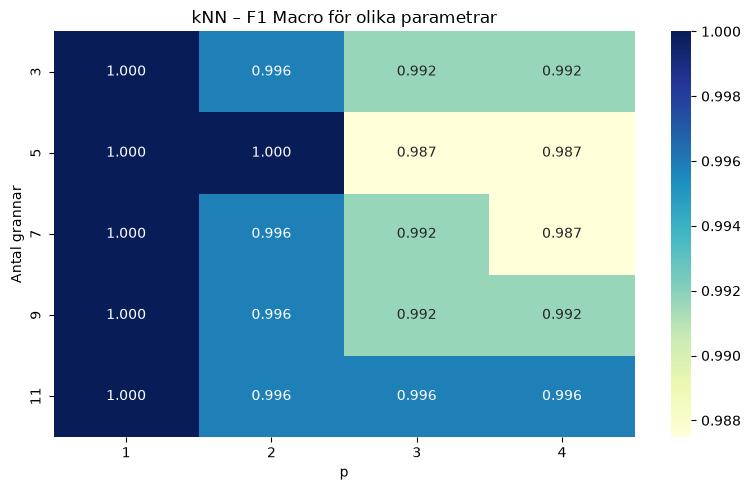

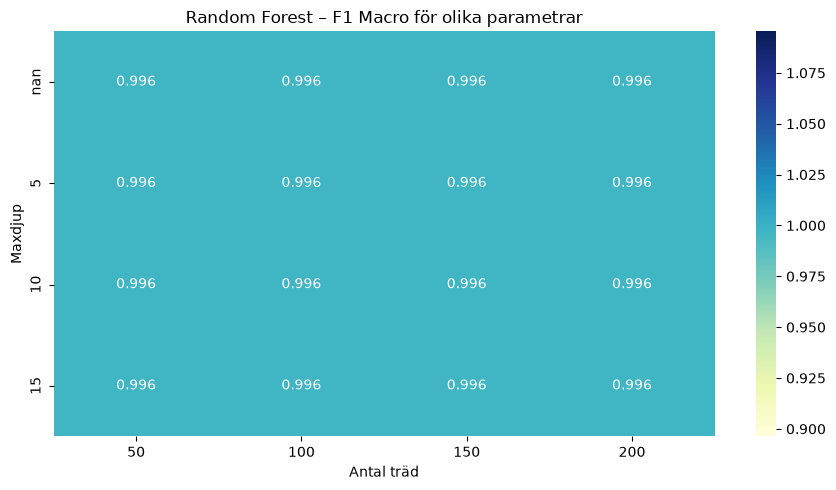

In [13]:

# ==========================================
# 8. VISUALISERA kNN
# ==========================================

knn_pivot = knn_results.pivot(
    index="param_classifier__n_neighbors",
    columns="param_classifier__p",
    values="mean_test_f1_macro"
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    knn_pivot,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)
plt.title("kNN – F1 Macro för olika parametrar")
plt.xlabel("p")
plt.ylabel("Antal grannar")
plt.tight_layout()
plt.show()


# ==========================================
# 9. VISUALISERA RANDOM FOREST
# ==========================================

rf_pivot = rf_results.pivot(
    index="param_max_depth",
    columns="param_n_estimators",
    values="mean_test_f1_macro"
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    rf_pivot,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)
plt.title("Random Forest – F1 Macro för olika parametrar")
plt.xlabel("Antal träd")
plt.ylabel("Maxdjup")
plt.tight_layout()
plt.show()


In [14]:

# ==========================================
# 10. VÄLJ DE BÄSTA MODELLERNA
# ==========================================

best_knn = knn_grid.best_estimator_
best_rf = rf_grid.best_estimator_

best_models = {
    "kNN": best_knn,
    "Random Forest": best_rf
}


# ==========================================
# 11. JÄMFÖR 5-FOLD CV OCH LOO
# ==========================================

validation_results = []
predictions = {}

for model_name, model in best_models.items():

    # --------------------------------------
    # 5-fold Stratified Cross-Validation
    # --------------------------------------

    start = time.perf_counter()

    pred_5fold = cross_val_predict(
        model,
        X,
        y,
        cv=cv_5,
        n_jobs=-1
    )

    time_5fold = time.perf_counter() - start

    acc_5fold = accuracy_score(y, pred_5fold)
    f1_5fold = f1_score(
        y,
        pred_5fold,
        average="macro"
    )

    # --------------------------------------
    # Leave-One-Out Cross-Validation
    # --------------------------------------

    start = time.perf_counter()

    pred_loo = cross_val_predict(
        model,
        X,
        y,
        cv=loo,
        n_jobs=-1
    )

    time_loo = time.perf_counter() - start

    acc_loo = accuracy_score(y, pred_loo)
    f1_loo = f1_score(
        y,
        pred_loo,
        average="macro"
    )

    # Spara prediktionerna för felanalys
    predictions[model_name] = {
        "5-fold CV": pred_5fold,
        "LOO": pred_loo
    }

    # Lägg till resultaten
    validation_results.append({
        "Modell": model_name,
        "Validering": "5-fold CV",
        "Accuracy": acc_5fold,
        "F1 Macro": f1_5fold,
        "Tid (sekunder)": time_5fold
    })

    validation_results.append({
        "Modell": model_name,
        "Validering": "LOO",
        "Accuracy": acc_loo,
        "F1 Macro": f1_loo,
        "Tid (sekunder)": time_loo
    })


# ==========================================
# 12. RESULTATTABELL
# ==========================================

validation_df = pd.DataFrame(validation_results)

print("Jämförelse mellan 5-fold CV och LOO:")
display(validation_df.round(4))

validation_df.to_csv(
    "validation_comparison.csv",
    index=False
)


Jämförelse mellan 5-fold CV och LOO:


,Modell,Validering,Accuracy,F1 Macro,Tid (sekunder)
0,kNN,5-fold CV,1.0000,1.0000,0.0263
1,kNN,LOO,1.0000,1.0000,0.2552
2,Random Forest,5-fold CV,0.9958,0.9958,0.0750
3,Random Forest,LOO,0.9958,0.9958,1.8073


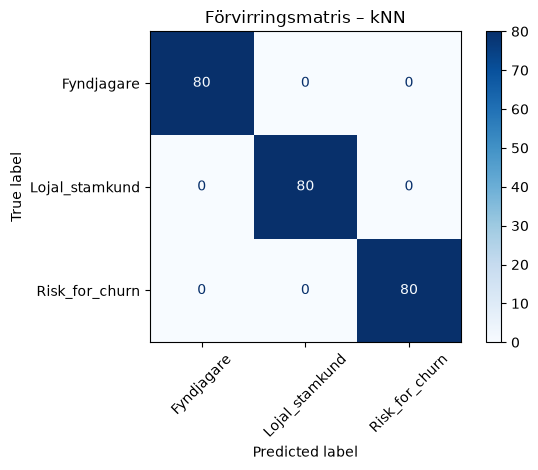

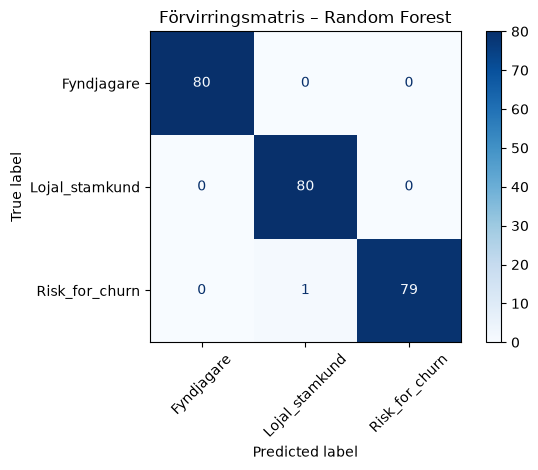

In [15]:

# ==========================================
# 13. FÖRVIRRINGSMATRISER
# ==========================================

class_labels = sorted(y.unique())

for model_name in best_models:

    pred = predictions[model_name]["5-fold CV"]

    cm = confusion_matrix(
        y,
        pred,
        labels=class_labels
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display_matrix.plot(
        cmap="Blues",
        xticks_rotation=45
    )

    plt.title(f"Förvirringsmatris – {model_name}")
    plt.tight_layout()
    plt.show()


In [16]:

# ==========================================
# 14. FELKLASSIFICERADE OBSERVATIONER
# ==========================================

for model_name in best_models:

    pred = predictions[model_name]["5-fold CV"]

    error_df = X.copy()

    error_df["Verklig klass"] = y
    error_df["Predikterad klass"] = pred

    errors = error_df[
        error_df["Verklig klass"] !=
        error_df["Predikterad klass"]
    ]

    print(f"\nFelklassificerade observationer – {model_name}")
    print("Antal fel:", len(errors))
    print("Andel fel:", round(len(errors) / len(y) * 100, 2), "%")

    display(errors.head(10))



Felklassificerade observationer – kNN
Antal fel: 0
Andel fel: 0.0 %


,besok_per_manad,snittorder_kr,tid_pa_sajt_sek,returgrad,kundtjanst_arenden,rabattkod_andel,Verklig klass,Predikterad klass



Felklassificerade observationer – Random Forest
Antal fel: 1
Andel fel: 0.42 %


,besok_per_manad,snittorder_kr,tid_pa_sajt_sek,returgrad,kundtjanst_arenden,rabattkod_andel,Verklig klass,Predikterad klass
49,11.2,1736.0,254.0,0.18,5.6,0.42,Risk_for_churn,Lojal_stamkund


Random Forest – Feature Importance:


,Variabel,Importance
3,returgrad,0.2567
1,snittorder_kr,0.2498
5,rabattkod_andel,0.1742
2,tid_pa_sajt_sek,0.1418
0,besok_per_manad,0.1065
4,kundtjanst_arenden,0.0710


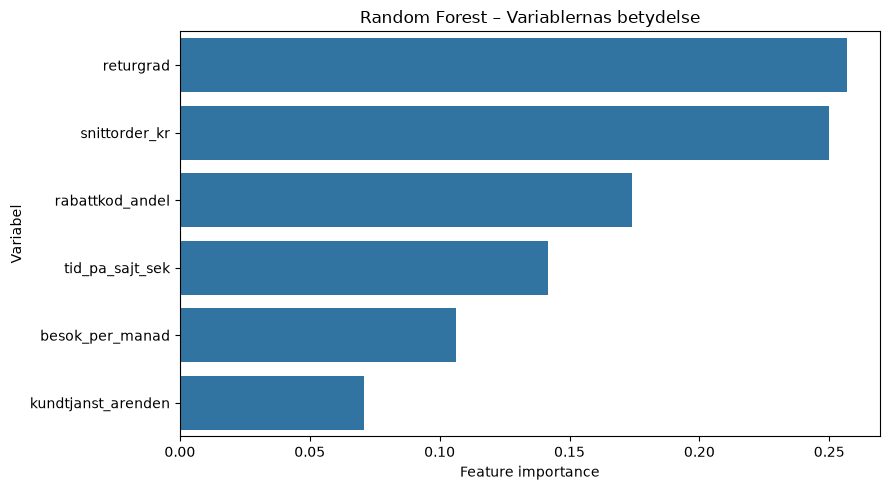

In [17]:

# ==========================================
# 15. FEATURE IMPORTANCE – RANDOM FOREST
# ==========================================

importance_df = pd.DataFrame({
    "Variabel": X.columns,
    "Importance": best_rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("Random Forest – Feature Importance:")
display(importance_df.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Variabel"
)

plt.title("Random Forest – Variablernas betydelse")
plt.xlabel("Feature importance")
plt.ylabel("Variabel")
plt.tight_layout()
plt.show()
